# 20 — Advanced practice: performance and reproducible pipelines

**Level:** Advanced engineering  
**Prerequisites:** 01 NumPy; 06 masks; 08 components; 18–19 projects

## What you will build and learn

- Turn exploratory cells into a reusable, validated function.
- Measure latency without assuming faster code is equally accurate.
- Save configuration, outputs, and environment information for reproducibility.

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Define an explicit input/output contract

A reliable function states what it accepts and returns. Our example counts bright
connected components on a dark background, assuming each one is a part. The
generated parts are circular, but this algorithm does not check circularity.
Inputs are non-empty `uint8` BGR arrays;
outputs include a binary mask and component measurements. Configuration is
separate from the algorithm, so experiments are easy to repeat.

Save the implementation to an ordinary Python module, then import it as a real
application would. The module is intentionally small and readable. `dataclass`
bundles named settings; `frozen=True` prevents accidental changes after creation.


In [2]:
from textwrap import dedent
import importlib.util

output_dir = ROOT / "outputs" / "20_engineering"
output_dir.mkdir(parents=True, exist_ok=True)
pipeline_source = dedent("""
from dataclasses import dataclass
import cv2
import numpy as np

@dataclass(frozen=True)
class Config:
    threshold: int = 130
    blur_size: int = 5
    min_area: int = 80

def analyze(image, config=Config()):
    if not isinstance(image, np.ndarray) or image.dtype != np.uint8:
        raise TypeError("Expected a NumPy uint8 image.")
    if image.ndim != 3 or image.shape[2] != 3 or image.size == 0:
        raise ValueError("Expected a non-empty H x W x 3 BGR image.")
    for name in ("threshold", "blur_size", "min_area"):
        value = getattr(config, name)
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)):
            raise ValueError(f"{name} must be an integer, excluding booleans.")
    if config.blur_size < 1 or config.blur_size % 2 != 1:
        raise ValueError("blur_size must be a positive odd integer.")
    if not 0 <= config.threshold <= 255 or config.min_area < 1:
        raise ValueError("threshold must be 0..255 and min_area positive.")
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    smooth = cv2.GaussianBlur(gray, (config.blur_size, config.blur_size), 0)
    _, mask = cv2.threshold(smooth, config.threshold, 255, cv2.THRESH_BINARY)
    count, labels, stats, centers = cv2.connectedComponentsWithStats(mask)
    filtered = np.zeros_like(mask)
    components = []
    for label in range(1, count):
        x, y, width, height, area = map(int, stats[label])
        if area >= config.min_area:
            filtered[labels == label] = 255
            components.append({"box": [x, y, width, height], "area": area,
                               "center": centers[label].tolist()})
    return {"mask": filtered, "components": components, "count": len(components)}
""").strip() + "\n"
module_path = output_dir / "parts_pipeline.py"
module_path.write_text(pipeline_source, encoding="utf-8")
spec = importlib.util.spec_from_file_location("parts_pipeline", module_path)
pipeline = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = pipeline  # dataclasses look up their defining module
spec.loader.exec_module(pipeline)
config = pipeline.Config()
print("Reusable module:", module_path)
print("Settings:", config)


Reusable module: C:\Users\Hareram ray\AI\OpencvPractical\outputs\20_engineering\parts_pipeline.py
Settings: Config(threshold=130, blur_size=5, min_area=80)


## Step 2 — Establish a correctness baseline

Generate five separate bright circles. The known mask is our pixel-level ground
truth. Count alone is insufficient: a badly segmented image can still have five
components. Use both count and IoU, then inspect the visual difference.


Count: 5 IoU: 0.9987


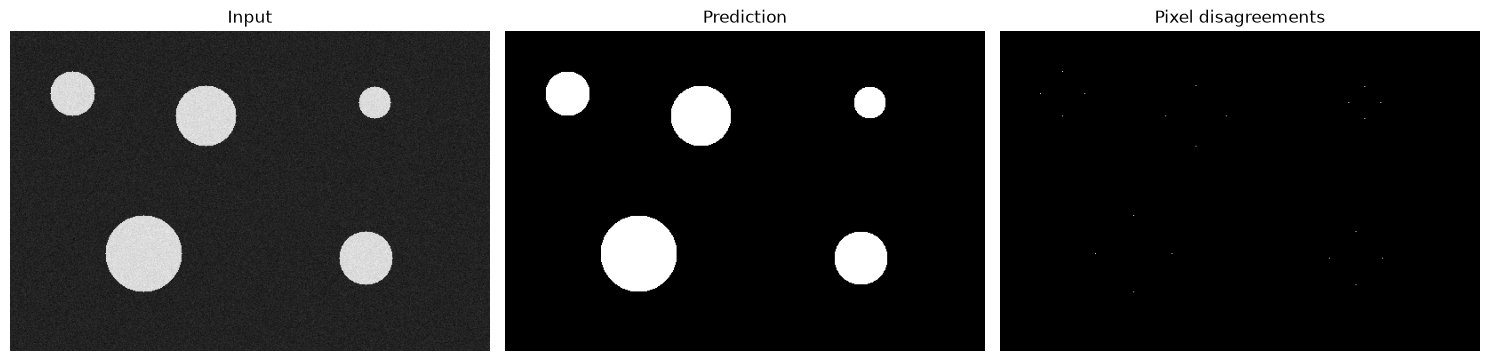

In [3]:
truth = np.zeros((360, 540), np.uint8)
for center, radius in [((70, 70), 25), ((220, 95), 34), ((410, 80), 18), ((150, 250), 43), ((400, 255), 30)]:
    cv2.circle(truth, center, radius, 255, -1)
gray = np.where(truth > 0, 220, 35).astype(np.uint8)
noise = np.random.default_rng(20).normal(0, 7, gray.shape)
gray = np.clip(gray.astype(np.float32) + noise, 0, 255).astype(np.uint8)
image = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

def mask_iou(a, b):
    a, b = a > 0, b > 0
    union = np.count_nonzero(a | b)
    return float(np.count_nonzero(a & b) / union) if union else 1.0

baseline = pipeline.analyze(image, config)
baseline_iou = mask_iou(baseline["mask"], truth)
print("Count:", baseline["count"], "IoU:", round(baseline_iou, 4))
assert baseline["count"] == 5
assert baseline_iou > 0.95, "The generated baseline should be segmented accurately."
show_images([image, baseline["mask"], cv2.absdiff(truth, baseline["mask"])], ["Input", "Prediction", "Pixel disagreements"])


## Step 3 — Benchmark the actual work

`perf_counter` measures elapsed wall time. Warmup calls reduce one-time setup
effects. Report a median and a high percentile over multiple runs; one timing
is noisy. These numbers describe this input and this computer. They do not
measure camera capture, disk I/O, display, or end-to-end application latency.


In [4]:
from time import perf_counter

def benchmark(function, repeats=15, warmup=3):
    for _ in range(warmup):
        function()
    durations = []
    for _ in range(repeats):
        start_time = perf_counter()
        function()
        durations.append((perf_counter() - start_time) * 1000)
    return {"median_ms": float(np.median(durations)), "p90_ms": float(np.percentile(durations, 90)), "repeats": repeats}

baseline_timing = benchmark(lambda: pipeline.analyze(image, config))
print(baseline_timing)
print("Approximate sequential compute-only FPS:", round(1000 / baseline_timing["median_ms"], 1))


{'median_ms': 0.9285002015531063, 'p90_ms': 1.180319907143712, 'repeats': 15}
Approximate sequential compute-only FPS: 1077.0


## Experiment A — Python loops versus array operations

All three implementations below add brightness with saturation at 255.
Converting to a wider type before NumPy arithmetic prevents `uint8` overflow.
Validate equal results **before** comparing speed. A faster answer with different
numeric behavior is not a drop-in optimization.


In [5]:
small = gray[:120, :180].copy()
def brighten_loop(source, amount=40):
    destination = np.empty_like(source)
    for row in range(source.shape[0]):
        for column in range(source.shape[1]):
            destination[row, column] = min(255, int(source[row, column]) + amount)
    return destination

def brighten_numpy(source, amount=40):
    return np.clip(source.astype(np.int16) + amount, 0, 255).astype(np.uint8)

loop_result = brighten_loop(small)
numpy_result = brighten_numpy(small)
opencv_result = cv2.add(small, 40)
assert np.array_equal(loop_result, numpy_result)
assert np.array_equal(loop_result, opencv_result)
brightness_timings = {
    "Python loop": benchmark(lambda: brighten_loop(small), repeats=5),
    "NumPy": benchmark(lambda: brighten_numpy(small)),
    "OpenCV": benchmark(lambda: cv2.add(small, 40)),
}
for name, timing in brightness_timings.items():
    print(name, timing)


Python loop {'median_ms': 5.065899807959795, 'p90_ms': 6.635420024394989, 'repeats': 5}
NumPy {'median_ms': 0.029900111258029938, 'p90_ms': 0.030379928648471832, 'repeats': 15}
OpenCV {'median_ms': 0.002800021320581436, 'p90_ms': 0.0028600916266441345, 'repeats': 15}


## Experiment B — Resolution versus quality

Smaller images have fewer pixels to process, but small objects and boundaries can
disappear. If width/height scale by `s`, area scales by `s²`, so we adjust minimum
component area accordingly. A fixed 5-pixel blur also covers more of the original
scene when downsampled: this experiment compares the complete scaled pipeline,
not an isolated pixel-count change.

Resize masks back with nearest-neighbor interpolation; linear interpolation
would introduce intermediate values into a categorical mask. Time resizing and
processing together. Compare IoU with the same full-resolution ground truth.


{'scale': 1.0, 'count': 5, 'IoU': 0.9986846432094706, 'median_ms': 1.524300081655383, 'p90_ms': 1.7502799164503813, 'repeats': 15}
{'scale': 0.5, 'count': 5, 'IoU': 0.9721642764015646, 'median_ms': 0.32659992575645447, 'p90_ms': 0.39498014375567436, 'repeats': 15}
{'scale': 0.25, 'count': 5, 'IoU': 0.9351214443434213, 'median_ms': 0.4096000920981169, 'p90_ms': 0.5388001445680857, 'repeats': 15}


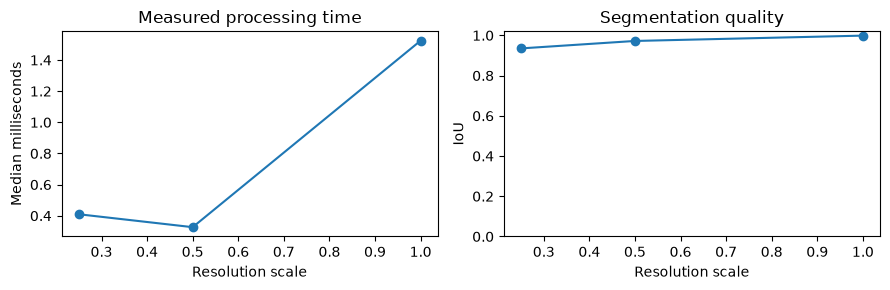

In [6]:
def analyze_scaled(scale):
    reduced = cv2.resize(image, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    scaled_config = pipeline.Config(threshold=config.threshold, blur_size=config.blur_size,
                                    min_area=max(1, round(config.min_area * scale * scale)))
    result = pipeline.analyze(reduced, scaled_config)
    restored = cv2.resize(result["mask"], (image.shape[1], image.shape[0]), interpolation=cv2.INTER_NEAREST)
    return restored, result["count"]

scale_rows = []
for scale in [1.0, 0.5, 0.25]:
    restored, count = analyze_scaled(scale)
    timing = benchmark(lambda: analyze_scaled(scale))
    scale_rows.append({"scale": scale, "count": count, "IoU": mask_iou(restored, truth), **timing})
for row in scale_rows:
    print(row)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot([r["scale"] for r in scale_rows], [r["median_ms"] for r in scale_rows], "o-")
axes[0].set(xlabel="Resolution scale", ylabel="Median milliseconds", title="Measured processing time")
axes[1].plot([r["scale"] for r in scale_rows], [r["IoU"] for r in scale_rows], "o-")
axes[1].set(xlabel="Resolution scale", ylabel="IoU", ylim=(0, 1.02), title="Segmentation quality")
plt.tight_layout()
plt.show()
plt.close(fig)


## Step 4 — Understand copies, views, and memory

A NumPy slice usually shares memory with its parent. Editing the slice can change
the original. `.copy()` creates independent pixels at a memory cost. `nbytes`
reports the array's element storage; a view's `nbytes` is its logical size, not
extra allocated memory. This distinction matters when processing large video.


BGR uint8 storage MiB: 0.556182861328125
BGR float32 storage MiB: 2.2247314453125


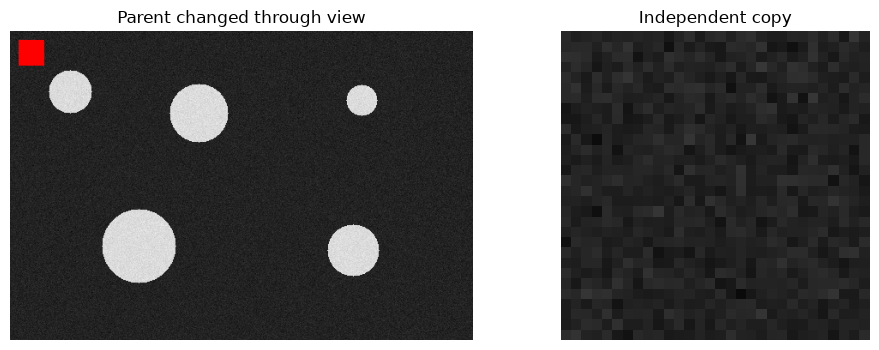

In [7]:
scratch = image.copy()
view = scratch[10:40, 10:40]
independent = scratch[10:40, 10:40].copy()
view[:] = (0, 0, 255)
assert np.shares_memory(view, scratch)
assert not np.shares_memory(independent, scratch)
print("BGR uint8 storage MiB:", image.nbytes / 1024**2)
print("BGR float32 storage MiB:", image.astype(np.float32).nbytes / 1024**2)
show_images([scratch, independent], ["Parent changed through view", "Independent copy"])


## Step 5 — Test useful behavior, including failures

Empty inputs and invalid settings should fail clearly. A blank scene should
return zero parts, and an analysis should not modify its input. These checks
protect an API contract; they do not prove accuracy on real-world images.
Expected errors are caught intentionally so Run All can finish.


In [8]:
before = image.copy()
pipeline.analyze(image, config)
assert np.array_equal(image, before), "The pipeline must not alter its input."
blank = np.zeros_like(image)
assert pipeline.analyze(blank, config)["count"] == 0
for invalid_input in [np.zeros((0, 0, 3), np.uint8), gray, image.astype(np.float32)]:
    try:
        pipeline.analyze(invalid_input, config)
    except (TypeError, ValueError) as error:
        print("Expected rejection:", error)
    else:
        raise AssertionError("Invalid input was accepted.")
for invalid_blur in [4, 5.0, True]:
    try:
        pipeline.analyze(image, pipeline.Config(blur_size=invalid_blur))
    except ValueError as error:
        print("Expected configuration rejection:", error)
    else:
        raise AssertionError("Invalid blur size was accepted.")


Expected rejection: Expected a non-empty H x W x 3 BGR image.
Expected rejection: Expected a non-empty H x W x 3 BGR image.
Expected rejection: Expected a NumPy uint8 image.
Expected configuration rejection: blur_size must be a positive odd integer.
Expected configuration rejection: blur_size must be an integer, excluding booleans.
Expected configuration rejection: blur_size must be an integer, excluding booleans.


## Step 6 — Save enough information to repeat an experiment

Save settings, versions, an input checksum, output mask, and measurements. A
checksum identifies bytes but does not preserve them, so also save the input.
`sha256(image.tobytes())` hashes the array pixels in this example, not PNG bytes.
Hardware and system load still affect timing; no fixed speed is guaranteed.


In [9]:
import hashlib
import json
import platform
from dataclasses import asdict

save_image(output_dir / "input.png", image)
save_image(output_dir / "prediction.png", baseline["mask"])
experiment = {
    "config": asdict(config), "opencv": cv2.__version__, "numpy": np.__version__,
    "python": platform.python_version(), "platform": platform.platform(),
    "opencv_threads": cv2.getNumThreads(), "input_shape": list(image.shape),
    "input_dtype": str(image.dtype), "input_pixels_sha256": hashlib.sha256(image.tobytes()).hexdigest(),
    "count": baseline["count"], "IoU": baseline_iou, "timing": baseline_timing,
    "scale_experiments": scale_rows,
}
report_path = output_dir / "experiment.json"
report_path.write_text(json.dumps(experiment, indent=2), encoding="utf-8")
saved = json.loads(report_path.read_text(encoding="utf-8"))
replay = pipeline.analyze(load_image(output_dir / "input.png"), pipeline.Config(**saved["config"]))
assert np.array_equal(replay["mask"], baseline["mask"])
print("Replay reproduced the mask. Report:", report_path)


Replay reproduced the mask. Report: C:\Users\Hareram ray\AI\OpencvPractical\outputs\20_engineering\experiment.json


## Exercises — Try first

1. Write a function that returns the largest component's area, or zero when no
   component is found. Check both cases.
2. Choose a resolution from the measured rows subject to IoU ≥ 0.95 and correct
   object count. Explain why the choice may differ on another machine.
3. Add a very small object and a touching pair. Which assumptions break, and which
   prior lesson suggests a remedy?
4. Copy the exported module into your own application and write a batch loop over
   personal images. Save per-image errors instead of silently skipping failures.


In [10]:
# Your experiments go here.


## Worked solutions and discussion


In [11]:
def largest_area(result):
    return max((component["area"] for component in result["components"]), default=0)

assert largest_area(pipeline.analyze(blank, config)) == 0
assert largest_area(baseline) > 0
print("Largest component:", largest_area(baseline))
eligible = [row for row in scale_rows if row["IoU"] >= 0.95 and row["count"] == 5]
if eligible:
    choice = min(eligible, key=lambda row: row["median_ms"])
    print("Fastest eligible measured configuration:", choice)
else:
    print("No measured setting meets the quality target. Improve the pipeline first.")


Largest component: 5785
Fastest eligible measured configuration: {'scale': 0.5, 'count': 5, 'IoU': 0.9721642764015646, 'median_ms': 0.32659992575645447, 'p90_ms': 0.39498014375567436, 'repeats': 15}


Minimum-area filtering can remove small true objects. Touching objects form one
connected component; notebook 11's distance-transform/watershed approach may help.
Neither change is automatically better: compare on representative labeled data.

## Independent final project

Choose one: count tabletop objects; align repeated photos; track a colored marker;
scan documents; or inspect a stable part. Define inputs, outputs, success criteria,
and failure conditions before coding. Collect multiple lighting conditions and
keep a final set untouched during tuning.

Deliver a working notebook, a reusable processing function, a labeled evaluation
set, quantitative results, failure-case images, and a short explanation of the
quality/performance tradeoff. Add video capture only if the application needs it;
measure capture and display time separately from processing.

## Completion checklist

- Explain array layout, data types, color order, interpolation, and masks.
- Choose an algorithm based on image formation and scene assumptions.
- Evaluate on data that did not guide parameter selection.
- Diagnose errors visually and with appropriate metrics.
- Reproduce an experiment from saved input and settings.
- Profile before optimizing, then recheck output quality.

You now have a foundation for more specialized work: robust real-camera geometry,
large-dataset evaluation, learned detection/segmentation, and application design.
Further expertise comes from applying these habits to unfamiliar failure cases.

**Reference:** [OpenCV performance measurement and improvement](https://docs.opencv.org/4.x/dc/d71/tutorial_py_optimization.html).
